Cell 1 – Import required libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


Cell 2 – Upload and extract dataset


In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('/content/water_potability.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Saving water_potability.csv to water_potability (1).csv
Dataset loaded successfully!
Dataset shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


Cell 3 – Dataset information

In [ ]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Description:")
display(df.describe())

print("\nColumn Names:")
print(df.columns)

print("\nDataset Shape:")
print(df.shape)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB
None

Statistical Description:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000



Column Names:
Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='object')

Dataset Shape:
(3276, 10)


Cell 4 – Check missing values

Missing Values:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64


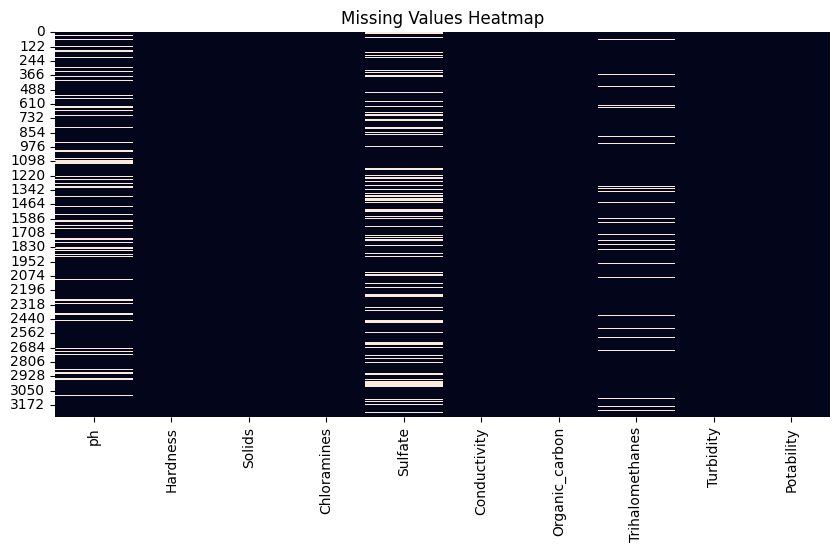

In [ ]:
print("Missing Values:")

print(df.isnull().sum())

plt.figure(figsize=(10,5))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values Heatmap")

plt.show()

Cell 5 – Remove duplicate records

In [ ]:
print("Duplicates before removal:",
      df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after removal:",
      df.duplicated().sum())

print("New dataset shape:", df.shape)

Duplicates before removal: 0
Duplicates after removal: 0
New dataset shape: (3276, 10)


Cell 6 – Outlier detection using IQR

In [ ]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.drop('Potability')

outlier_counts = {}

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) |
             (df[col] > upper)).sum()

    outlier_counts[col] = count

print("Outlier counts:")

print(pd.Series(outlier_counts))

Outlier counts:
ph                 46
Hardness           83
Solids             47
Chloramines        61
Sulfate            41
Conductivity       11
Organic_carbon     25
Trihalomethanes    33
Turbidity          19
dtype: int64


Cell 7 – Visualize outliers

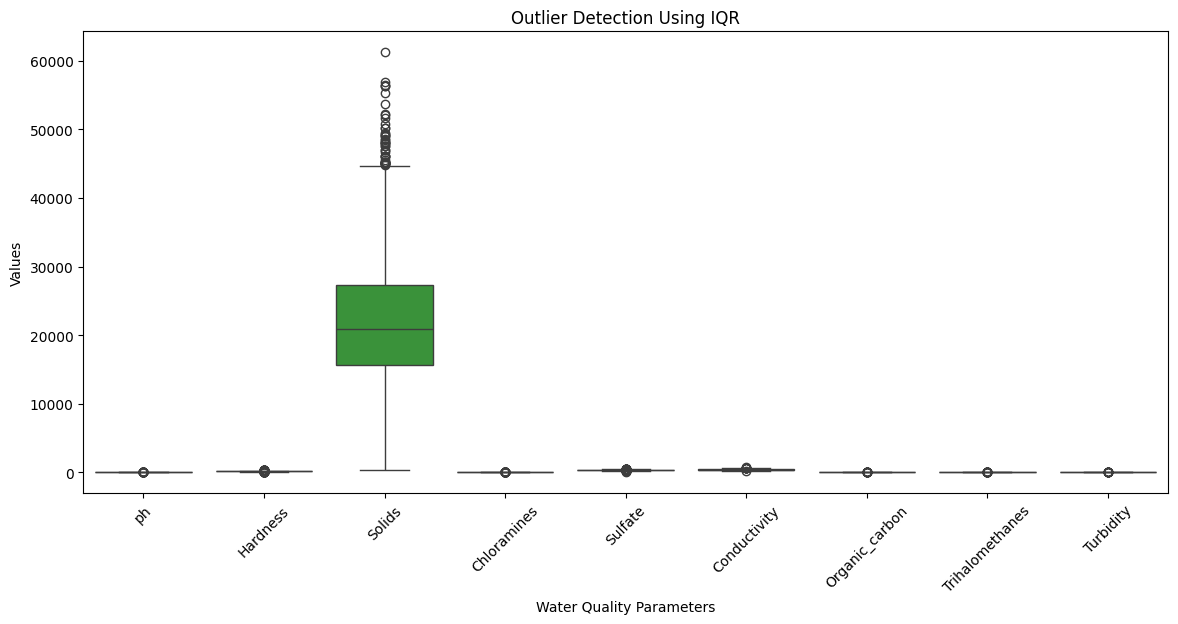

In [ ]:
plt.figure(figsize=(14,6))

sns.boxplot(data=df[numeric_columns])

plt.title("Outlier Detection Using IQR")

plt.xticks(rotation=45)

plt.xlabel("Water Quality Parameters")

plt.ylabel("Values")

plt.show()

Potability Class Distribution
Potability
0    1998
1    1278
Name: count, dtype: int64


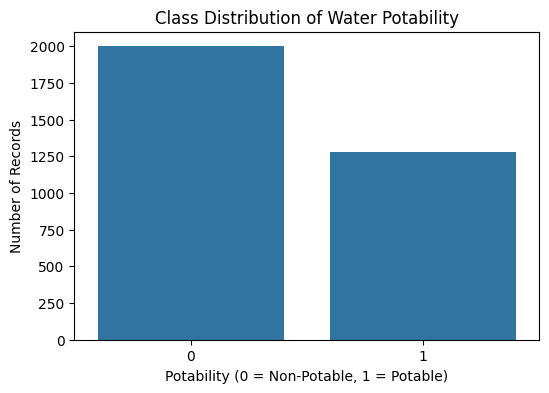

In [ ]:
print("Potability Class Distribution")

print(df['Potability'].value_counts())

plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x='Potability'
)

plt.title("Class Distribution of Water Potability")

plt.xlabel("Potability (0 = Non-Potable, 1 = Potable)")

plt.ylabel("Number of Records")

plt.show()

Separate input and output features

In [ ]:
X = df.drop('Potability', axis=1)

y = df['Potability']

print("Input Features Shape:", X.shape)

print("Target Variable Shape:", y.shape)

print("\nInput Features:")

print(X.columns.tolist())

Input Features Shape: (3276, 9)
Target Variable Shape: (3276,)

Input Features:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']


Split training and testing data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

print("\nTraining Class Distribution:")

print(y_train.value_counts())

print("\nTesting Class Distribution:")

print(y_test.value_counts())

Training Data: (2620, 9)
Testing Data: (656, 9)

Training Class Distribution:
Potability
0    1598
1    1022
Name: count, dtype: int64

Testing Class Distribution:
Potability
0    400
1    256
Name: count, dtype: int64


– Handle missing values

In [ ]:
imputer = SimpleImputer(strategy='median')

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing Values Before Imputation:")

print(X_train.isnull().sum())

print("\nMissing Values After Imputation:")

print(X_train_imputed.isnull().sum())

Missing Values Before Imputation:
ph                 387
Hardness             0
Solids               0
Chloramines          0
Sulfate            625
Conductivity         0
Organic_carbon       0
Trihalomethanes    134
Turbidity            0
dtype: int64

Missing Values After Imputation:
ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
dtype: int64


Feature scaling

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_imputed
)

X_test_scaled = scaler.transform(
    X_test_imputed
)

print("Feature Scaling Completed!")

print("Scaled Training Data:", X_train_scaled.shape)

print("Scaled Testing Data:", X_test_scaled.shape)

Feature Scaling Completed!
Scaled Training Data: (2620, 9)
Scaled Testing Data: (656, 9)


Define machine learning models

In [ ]:
models = {

    "Random Forest":
    RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees":
    ExtraTreesClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting":
    GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ),

    "Hist Gradient Boosting":
    HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    ),

    "Logistic Regression":
    LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ),

    "SVM":
    SVC(
        C=2,
        kernel='rbf',
        probability=True,
        class_weight='balanced',
        random_state=42
    ),

    "KNN":
    KNeighborsClassifier(
        n_neighbors=15
    )
}

print("Seven ML Models Defined Successfully!")

Seven ML Models Defined Successfully!


Train all machine learning models

In [ ]:
trained_models = {}

for name, model in models.items():

    if name in [
        "Logistic Regression",
        "SVM",
        "KNN"
    ]:

        model.fit(
            X_train_scaled,
            y_train
        )

    else:

        model.fit(
            X_train_imputed,
            y_train
        )

    trained_models[name] = model

    print(name, "Training Completed!")

print("\nAll Models Trained Successfully!")

Random Forest Training Completed!
Extra Trees Training Completed!
Gradient Boosting Training Completed!
Hist Gradient Boosting Training Completed!
Logistic Regression Training Completed!
SVM Training Completed!
KNN Training Completed!

All Models Trained Successfully!


Predict using all models

In [ ]:
predictions = {}

for name, model in trained_models.items():

    if name in [
        "Logistic Regression",
        "SVM",
        "KNN"
    ]:

        predictions[name] = model.predict(
            X_test_scaled
        )

    else:

        predictions[name] = model.predict(
            X_test_imputed
        )

print("Predictions Completed!")

Predictions Completed!


Evaluate model performance

In [ ]:
results = []

for name, model in trained_models.items():

    y_pred = predictions[name]

    if name in [
        "Logistic Regression",
        "SVM",
        "KNN"
    ]:

        probabilities = model.predict_proba(
            X_test_scaled
        )[:, 1]

    else:

        probabilities = model.predict_proba(
            X_test_imputed
        )[:, 1]

    results.append({

        'Model': name,

        'Accuracy': accuracy_score(
            y_test, y_pred
        ) * 100,

        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ) * 100,

        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ) * 100,

        'F1 Score': f1_score(
            y_test, y_pred, zero_division=0
        ) * 100,

        'ROC-AUC': roc_auc_score(
            y_test, probabilities
        )

    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
)

display(results_df.round(2))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Hist Gradient Boosting,67.68,67.74,32.81,44.21,0.65
1,Extra Trees,66.77,63.19,35.55,45.50,0.66
0,Random Forest,65.70,60.26,35.55,44.72,0.67
2,Gradient Boosting,63.41,61.43,16.80,26.38,0.62
5,SVM,62.20,51.59,50.78,51.18,0.65
6,KNN,61.74,52.14,23.83,32.71,0.61
4,Logistic Regression,52.44,41.46,53.12,46.58,0.55


compare the accuracy models


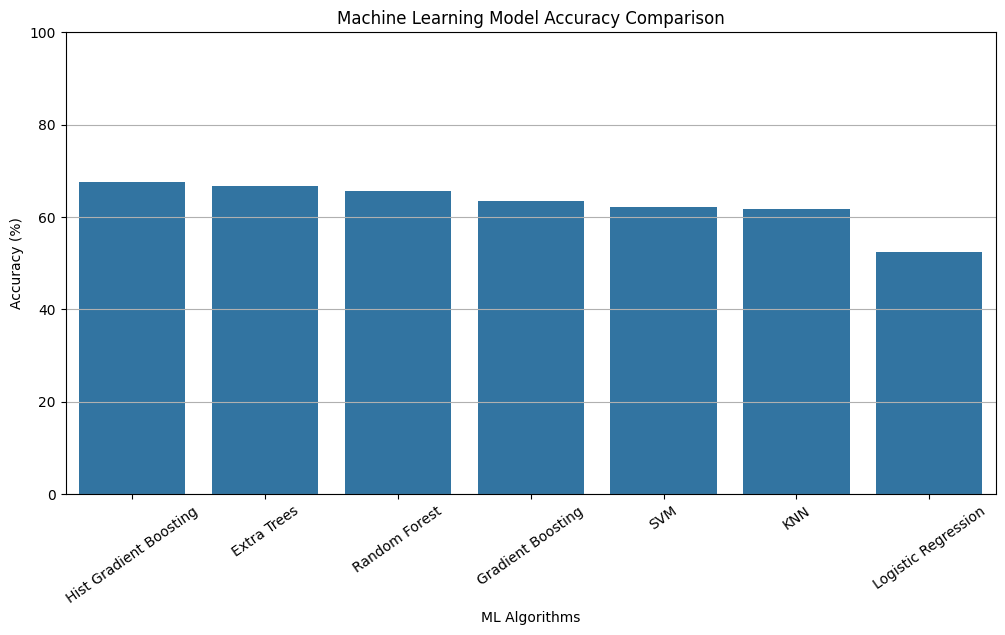

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title("Machine Learning Model Accuracy Comparison")

plt.xlabel("ML Algorithms")

plt.ylabel("Accuracy (%)")

plt.xticks(rotation=35)

plt.ylim(0,100)

plt.grid(axis='y')

plt.show()

Find the best-performing model

In [ ]:
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

best_prediction = predictions[best_model_name]

print("Best Performing Model:", best_model_name)

print(
    "Accuracy:",
    round(
        accuracy_score(y_test, best_prediction) * 100,
        2
    ),
    "%"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        best_prediction,
        target_names=[
            'Non-Potable',
            'Potable'
        ]
    )
)

Best Performing Model: Hist Gradient Boosting
Accuracy: 67.68 %

Classification Report:
              precision    recall  f1-score   support

 Non-Potable       0.68      0.90      0.77       400
     Potable       0.68      0.33      0.44       256

    accuracy                           0.68       656
   macro avg       0.68      0.61      0.61       656
weighted avg       0.68      0.68      0.64       656



Confusion matrix

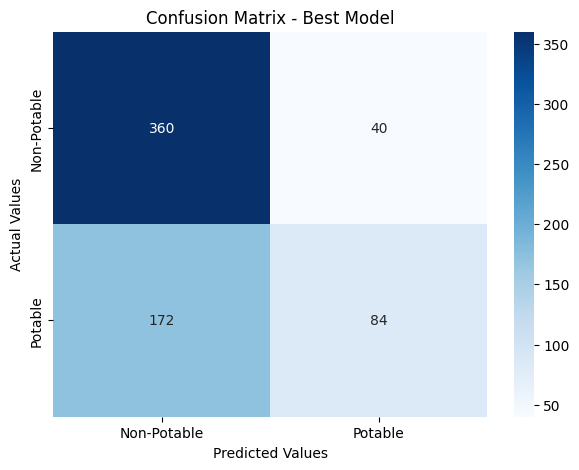

In [ ]:
cm = confusion_matrix(
    y_test,
    best_prediction
)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',

    xticklabels=[
        'Non-Potable',
        'Potable'
    ],

    yticklabels=[
        'Non-Potable',
        'Potable'
    ]
)

plt.title("Confusion Matrix - Best Model")

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.show()

ROC curve for all models

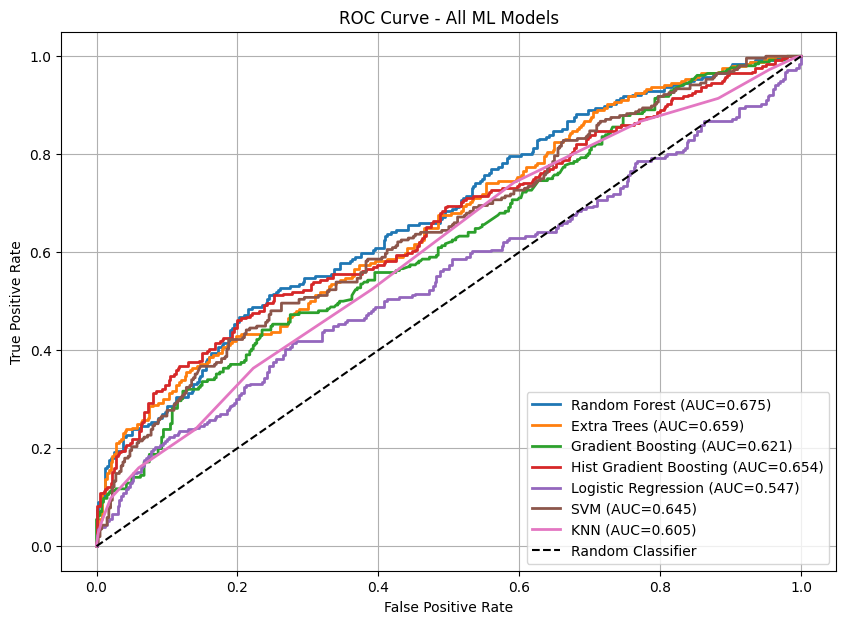

In [ ]:
plt.figure(figsize=(10,7))

for name, model in trained_models.items():

    if name in [
        "Logistic Regression",
        "SVM",
        "KNN"
    ]:

        probability = model.predict_proba(
            X_test_scaled
        )[:, 1]

    else:

        probability = model.predict_proba(
            X_test_imputed
        )[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probability
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{name} (AUC={roc_auc:.3f})'
    )

plt.plot(
    [0,1],
    [0,1],
    'k--',
    label='Random Classifier'
)

plt.title("ROC Curve - All ML Models")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend(loc='lower right')

plt.grid()

plt.show()

Individual ROC curve of the best model

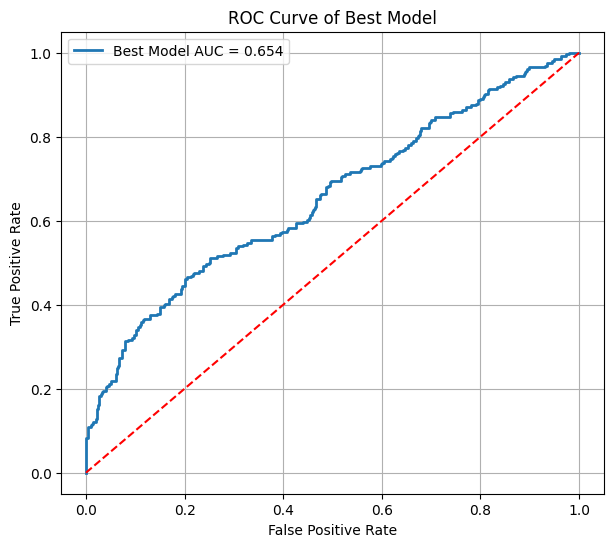

Best Model: Hist Gradient Boosting
ROC-AUC: 0.6539


In [ ]:
if best_model_name in [
    "Logistic Regression",
    "SVM",
    "KNN"
]:

    best_probability = best_model.predict_proba(
        X_test_scaled
    )[:, 1]

else:

    best_probability = best_model.predict_proba(
        X_test_imputed
    )[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    best_probability
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f'Best Model AUC = {roc_auc:.3f}'
)

plt.plot(
    [0,1],
    [0,1],
    'r--'
)

plt.title("ROC Curve of Best Model")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.grid()

plt.show()

print("Best Model:", best_model_name)

print("ROC-AUC:", round(roc_auc,4))

Explainable AI using Feature Importance

,Feature,Importance
4,Sulfate,0.080030
0,ph,0.070427
1,Hardness,0.037805
3,Chloramines,0.028354
2,Solids,0.023171
6,Organic_carbon,0.009451
5,Conductivity,0.006555
7,Trihalomethanes,0.005183
8,Turbidity,-0.002591


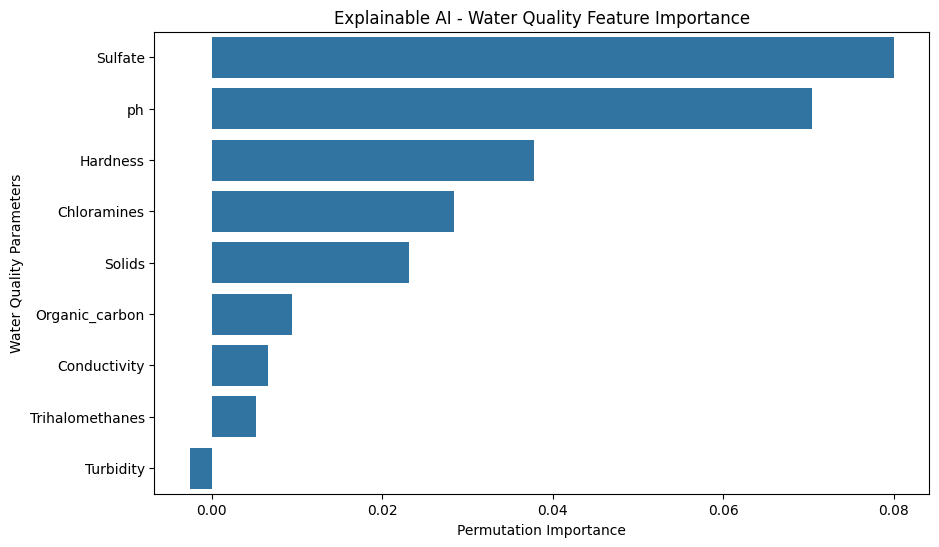

In [ ]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='accuracy'
)

feature_importance = pd.DataFrame({

    'Feature': X.columns,

    'Importance': importance.importances_mean

})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Explainable AI - Water Quality Feature Importance")

plt.xlabel("Permutation Importance")

plt.ylabel("Water Quality Parameters")

plt.show()

Predict water potability using new input

In [ ]:
new_water = pd.DataFrame([{

    'ph': 7.2,

    'Hardness': 200,

    'Solids': 15000,

    'Chloramines': 7,

    'Sulfate': 300,

    'Conductivity': 400,

    'Organic_carbon': 10,

    'Trihalomethanes': 60,

    'Turbidity': 3

}])

if best_model_name in [
    "Logistic Regression",
    "SVM",
    "KNN"
]:

    new_input = imputer.transform(new_water)

    new_input = scaler.transform(new_input)

else:

    new_input = imputer.transform(new_water)

prediction = best_model.predict(new_input)

probability = best_model.predict_proba(new_input)

print("Selected Model:", best_model_name)

print("Potability Prediction:")

if prediction[0] == 1:

    print("Water is predicted as POTABLE")

else:

    print("Water is predicted as NON-POTABLE")

print(
    "Predicted class probability:",
    round(probability[0][prediction[0]] * 100, 2),
    "%"
)

Selected Model: Hist Gradient Boosting
Potability Prediction:
Water is predicted as NON-POTABLE
Predicted class probability: 71.35 %


Save the trained model

In [ ]:
import joblib

model_package = {

    'model': best_model,

    'imputer': imputer,

    'scaler': scaler,

    'model_name': best_model_name,

    'features': X.columns.tolist()

}

joblib.dump(
    model_package,
    'water_quality_model.pkl'
)

print("Model saved successfully!")

files.download('water_quality_model.pkl')

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Final project results


In [ ]:
print("=" * 50)

print("PREDICTIVE WATER QUALITY ASSESSMENT")

print("=" * 50)

print("\nDataset Records:", len(df))

print("Input Features:", X.shape[1])

print("ML Models Used:", len(trained_models))

print("\nBest Model:", best_model_name)

print(
    "Best Model Accuracy:",
    round(
        accuracy_score(y_test, best_prediction) * 100,
        2
    ),
    "%"
)

print("ROC-AUC Score:", round(roc_auc, 4))

print("\nModel Comparison:")

display(results_df.round(2))

print("=" * 50)

print("PROJECT EXECUTION COMPLETED!")

PREDICTIVE WATER QUALITY ASSESSMENT

Dataset Records: 3276
Input Features: 9
ML Models Used: 7

Best Model: Hist Gradient Boosting
Best Model Accuracy: 67.68 %
ROC-AUC Score: 0.6539

Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Hist Gradient Boosting,67.68,67.74,32.81,44.21,0.65
1,Extra Trees,66.77,63.19,35.55,45.50,0.66
0,Random Forest,65.70,60.26,35.55,44.72,0.67
2,Gradient Boosting,63.41,61.43,16.80,26.38,0.62
5,SVM,62.20,51.59,50.78,51.18,0.65
6,KNN,61.74,52.14,23.83,32.71,0.61
4,Logistic Regression,52.44,41.46,53.12,46.58,0.55


PROJECT EXECUTION COMPLETED!
